# 03 — Training monitoring and failure diagnosis (deliverable 2)

Two questions about the feed-forward network of notebook 02:

1. **Is the training itself working?** Two sanity checks: the initial loss, and overfitting a single batch.
2. **Why doesn't the network generalise?** A learning-rate sweep, the overfitting of the large network at 128 px, and a learning curve.
3. **What fixes it?** An ablation of the fixes (A7), and the frozen FFN candidate.

Each experiment ends with **what we see / why / fix**. Setup from notebook 02: 32 px inputs, hidden layers 256 and 128, Adam, batches of 64. Everything is measured on the validation set.

In [1]:
import math
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

sys.path.insert(0, "../src")
from museum.data import ROOT, get_arrays, get_loaders, norm_stats
from museum.diagnostics import dead_relu_fraction, overfit_one_batch
from museum.evaluation import benchmark_latency, model_size_mb, save_result, total_parameters
from museum.models import FFN_CANDIDATE, FFN_RECIPE, StyleMLP, TorchPredictor, count_parameters
from museum.train import evaluate, fit, get_device, predict, train_one_epoch

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: 1 seed and a few epochs, for a quick check
EPOCHS = 8 if FAST_RUN else 40
SEEDS = [0] if FAST_RUN else [0, 1, 2]
SIZE = 32            # chosen in notebook 02
HIDDEN = (256, 128)
BATCH_SIZE = 64

torch.manual_seed(0)
device = get_device()
loss_fn = nn.CrossEntropyLoss()
FIG_DIR = ROOT / "results" / "figures"
RESULTS_DIR, CKPT_DIR = ROOT / "results", ROOT / "checkpoints"
train_dl, val_dl, _, classes = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE)
print("device:", device, "| FAST_RUN:", FAST_RUN, "| epochs:", EPOCHS, "| seeds:", SEEDS)

device: mps | FAST_RUN: False | epochs: 40 | seeds: [0, 1, 2]


## 1. Sanity check: the initial loss

Before any training, a network with no preference between 5 styles should give each a probability of 1/5, so a cross-entropy of ln 5 ≈ 1.609. Any other value points to a bug in the data, the labels or the initialisation.

In [2]:
torch.manual_seed(0)
model = StyleMLP(img_size=SIZE, hidden=HIDDEN).to(device)
initial_loss, initial_acc = evaluate(model, val_dl, loss_fn, device)
assert abs(initial_loss - math.log(5)) < 0.05, "the initial loss should be ln 5"
print(f"initial validation loss {initial_loss:.4f} (ln 5 = {math.log(5):.4f}), accuracy {initial_acc:.3f}")

initial validation loss 1.6098 (ln 5 = 1.6094), accuracy 0.156


**What we see.** Initial loss 1.610 vs ln 5 = 1.609: the data, the labels and the initialisation are consistent.

## 2. Sanity check: overfitting one batch

The network should be able to memorise 32 images: if it can't drive the loss on one fixed batch to almost 0, something is broken (the loss, the labels, the optimiser, the gradients), and no amount of data or tuning will help.

loss: step 1 1.598, step 300 0.00000; below 0.05 from step 7


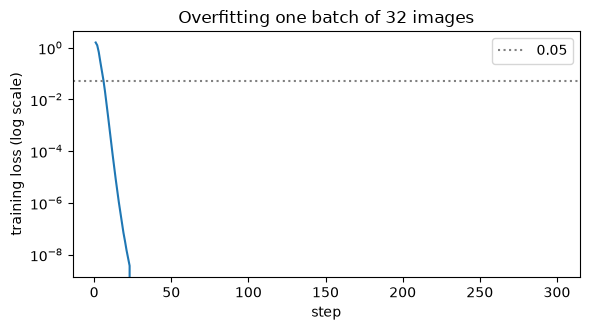

In [3]:
xb, yb = next(iter(DataLoader(train_dl.dataset, batch_size=32)))   # the same 32 images at every step
xb, yb = xb.to(device), yb.to(device)
torch.manual_seed(0)
model = StyleMLP(img_size=SIZE, hidden=HIDDEN).to(device)
losses = overfit_one_batch(model, xb, yb, torch.optim.Adam(model.parameters(), lr=1e-3), steps=300)
first_below = next(i for i, loss in enumerate(losses) if loss < 0.05) + 1
print(f"loss: step 1 {losses[0]:.3f}, step 300 {losses[-1]:.5f}; below 0.05 from step {first_below}")
assert losses[-1] < 0.05, "one batch should be overfitted"

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, len(losses) + 1), losses)
ax.axhline(0.05, color="grey", ls=":", label="0.05")
ax.set(yscale="log", xlabel="step", ylabel="training loss (log scale)", title="Overfitting one batch of 32 images")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_one_batch.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** The loss on the fixed batch falls below 0.05 by step 7 and reaches about 0 by step 300.

**Why it matters.** The network, the loss and the optimiser work together. From here on, every failure is about **generalisation**, not a bug.

## 3. Learning-rate sweep

Adam at five learning rates, 3 seeds each. After training we also measure the share of **dead ReLU units**: units that output 0 for every validation image, so they no longer pass any gradient.

**Rule, fixed before looking at the results:** keep the learning rate with the highest mean best validation accuracy. It is used for the rest of the FFN work (ablation A7).

chosen learning rate: 0.0001


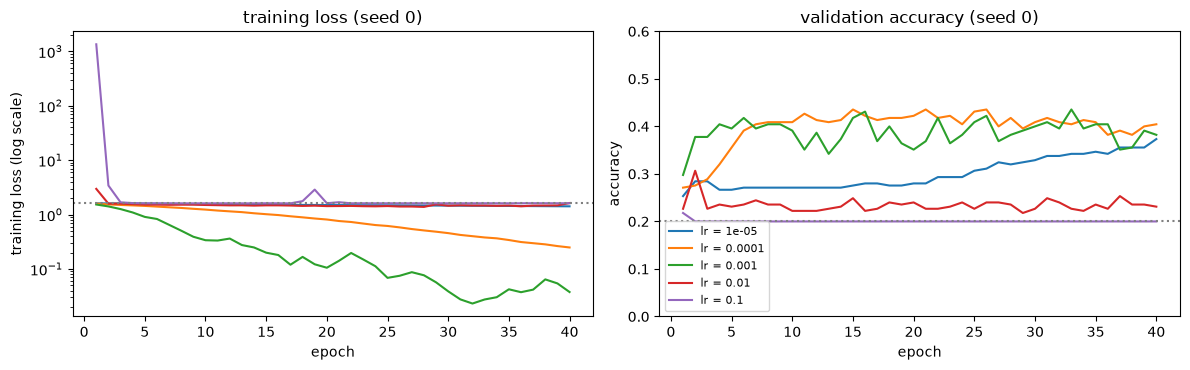

,best val acc (mean),best val acc (std),lowest val loss (mean),lowest val loss (std),final train loss (mean),final train loss (std),"dead ReLUs, layer 1 (mean)","dead ReLUs, layer 1 (std)","dead ReLUs, layer 2 (mean)","dead ReLUs, layer 2 (std)"
lr,,,,,,,,,,
0.00001,0.357,0.014,1.475,0.004,1.415,0.003,0.0,0.0,0.000,0.000
0.00010,0.440,0.008,1.408,0.005,0.263,0.015,0.0,0.0,0.000,0.000
0.00100,0.430,0.007,1.462,0.017,0.056,0.025,0.0,0.0,0.003,0.005
0.01000,0.293,0.027,1.555,0.024,1.524,0.126,0.0,0.0,0.961,0.028
0.10000,0.206,0.010,1.649,0.069,1.615,0.002,0.0,0.0,0.995,0.009


In [4]:
LRS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
x_val = torch.cat([x for x, _ in val_dl]).to(device)
rows, curves = [], {}
for lr in LRS:
    for seed in SEEDS:
        train_dl, val_dl, _, _ = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE, seed=seed)
        torch.manual_seed(seed)
        model = StyleMLP(img_size=SIZE, hidden=HIDDEN)
        h = fit(model, train_dl, val_dl, loss_fn, torch.optim.Adam(model.parameters(), lr=lr), EPOCHS, device,
                verbose=False)
        if seed == SEEDS[0]:
            curves[lr] = h
        rows.append({"lr": lr, "seed": seed, "best val acc": max(h["val_acc"]), "lowest val loss": min(h["val_loss"]),
                     "final train loss": h["train_loss"][-1],
                     "dead ReLUs, layer 1": dead_relu_fraction(model, x_val)[0],
                     "dead ReLUs, layer 2": dead_relu_fraction(model, x_val)[1]})
sweep = pd.DataFrame(rows).groupby("lr").agg(["mean", "std"]).drop(columns="seed")
sweep.columns = [f"{metric} ({stat})" for metric, stat in sweep.columns]
LR = float(sweep["best val acc (mean)"].idxmax())
print(f"chosen learning rate: {LR:g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lr, h in curves.items():
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(epochs, h["train_loss"], label=f"lr = {lr:g}")
    axes[1].plot(epochs, h["val_acc"], label=f"lr = {lr:g}")
axes[0].axhline(math.log(5), color="grey", ls=":")
axes[1].axhline(0.2, color="grey", ls=":")
axes[0].set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="training loss (seed 0)")
axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0, 0.6), title="validation accuracy (seed 0)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_lr_sweep.png", dpi=150, bbox_inches="tight")
plt.show()
sweep.round(3)

**What we see** (Adam, 32 px, 40 epochs, 3 seeds):

| Learning rate | Behaviour | Best val acc |
|---|---|---|
| 1e-5 | too slow: after 40 epochs the training loss is still 1.42, barely below ln 5 | 0.357 |
| **1e-4** | smooth: the training loss falls steadily to 0.26; also the lowest validation loss (1.408) | **0.440 ± 0.008** |
| 1e-3 | fast but noisy: the training loss reaches 0.06 (memorised), and validation accuracy jumps around | 0.430 ± 0.007 |
| 1e-2 | broken: the training loss is stuck around 1.5; **96 %** of the second-layer ReLUs are dead | 0.293 |
| 1e-1 | diverges, then dies: the first epoch's loss reaches ~1,000, then **99.5 %** of the second-layer ReLUs are dead and the accuracy is chance | 0.206 |

**Why.**
- **Step size.** Too small a step barely moves the weights; too large a step overshoots.
- **Dead ReLUs.** With ReLU, one large update can push a unit's input below 0 for every image. The unit then outputs 0, receives no gradient, and never recovers: a **dead ReLU**.
- **A dead layer.** When almost the whole second layer is dead, the output layer receives zeros and predicts the same thing for every image, so the loss stays near ln 5 and the accuracy at chance.

**Fix.** Learning rate **1e-4** (rule above), used in the ablation (A7). 1e-3, used in notebook 02, is close in accuracy but memorises faster and is noisier.

## 4. Why doesn't it generalise? The large network at 128 px

The 128 px network has 12.6 M parameters for 1,050 training images. We train it with the chosen learning rate and record, at every epoch, the losses and accuracies and the network's **confidence** (its highest softmax probability) on the validation images it gets right and on those it gets wrong.

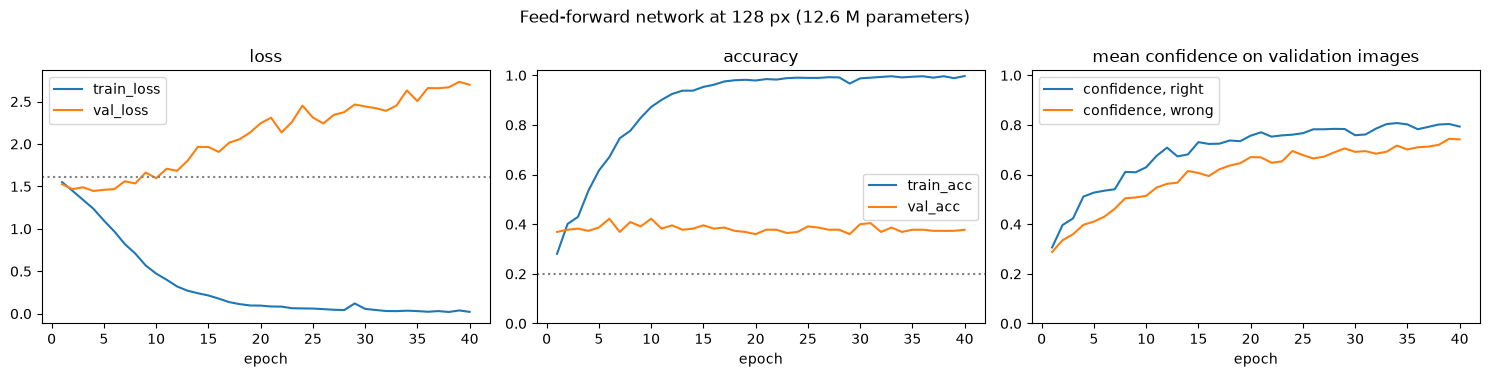

lowest validation loss at epoch 4: 1.446, val acc 0.373


,train_loss,val_loss,train_acc,val_acc,"confidence, right","confidence, wrong"
epoch,,,,,,
1,1.550,1.526,0.281,0.369,0.306,0.288
4,1.236,1.446,0.535,0.373,0.512,0.398
21,0.085,2.309,0.985,0.378,0.770,0.669
40,0.021,2.698,0.997,0.378,0.793,0.742


In [5]:
train_dl, val_dl, _, _ = get_loaders(img_size=128, batch_size=BATCH_SIZE, seed=0)
torch.manual_seed(0)
model = StyleMLP(img_size=128, hidden=HIDDEN).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
log = []
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _ = train_one_epoch(model, train_dl, loss_fn, optimizer, device)
    val_loss, _ = evaluate(model, val_dl, loss_fn, device)
    y_true, y_pred, probs = predict(model, val_dl, device)
    right, confidence = y_true == y_pred, probs.max(axis=1)
    log.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "train_acc": train_acc,
                "val_acc": right.mean(), "confidence, right": confidence[right].mean(),
                "confidence, wrong": confidence[~right].mean()})
log = pd.DataFrame(log).set_index("epoch")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
log[["train_loss", "val_loss"]].plot(ax=axes[0], title="loss")
log[["train_acc", "val_acc"]].plot(ax=axes[1], title="accuracy", ylim=(0, 1.02))
log[["confidence, right", "confidence, wrong"]].plot(ax=axes[2], ylim=(0, 1.02),
                                                     title="mean confidence on validation images")
axes[0].axhline(math.log(5), color="grey", ls=":")
axes[1].axhline(0.2, color="grey", ls=":")
fig.suptitle("Feed-forward network at 128 px (12.6 M parameters)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_overfitting_128px.png", dpi=150, bbox_inches="tight")
plt.show()

best = log["val_loss"].idxmin()
print(f"lowest validation loss at epoch {best}: {log.loc[best, 'val_loss']:.3f}, val acc {log.loc[best, 'val_acc']:.3f}")
log.iloc[[0, best - 1, len(log) // 2, -1]].round(3)

**What we see.**
- **Training:** the loss goes from 1.55 to 0.02 and the accuracy from 0.28 to 0.997. The network memorises the 1,050 images.
- **Validation:** the loss is lowest at epoch 4 (1.446, accuracy 0.373), then climbs to 2.70, while the accuracy stays flat between 0.36 and 0.42.
- **Confidence:** on the validation images it gets wrong, the mean confidence rises from 0.29 to 0.74, almost as high as on those it gets right (0.79).

**Why.** This is **overfitting** (high variance). With far more parameters than examples, the network fits details of individual training images (exact pixel values at exact positions) that don't carry over to new paintings. Its confidence grows on every image, right or wrong. That's why the validation loss rises while the accuracy doesn't move: cross-entropy punishes confident mistakes heavily.

**Consequence for the guide.** The network is barely more confident when right than when wrong, so the confidence of an unregularised FFN is a poor signal for the guide's "not sure" answer (A10).

**Fixes**, tested in the ablation (A7):
- fewer parameters per image (a smaller input: already 32 px)
- dropout
- weight decay
- augmentation
- early stopping on the validation loss (here it would stop at epoch 4)

## 5. Would more data help? Learning curve at 32 px

Same network, trained on 25 %, 50 %, 75 % and 100 % of the training images (stratified, 3 seeds), always evaluated on the full validation set. If validation accuracy is still rising at 100 %, the network is limited by the amount of data (high variance), not by its capacity.

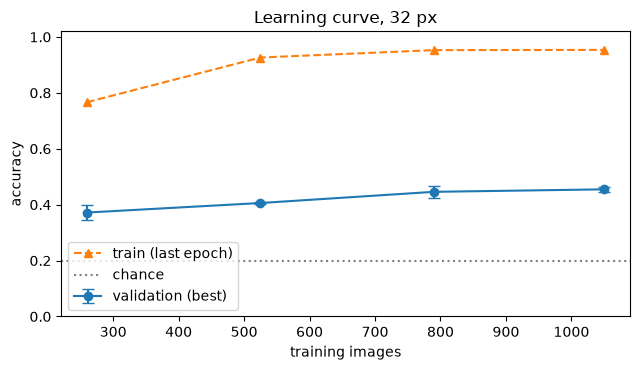

,best val acc (mean),best val acc (std),final train acc (mean),final train acc (std)
training images,,,,
260,0.372,0.026,0.767,0.055
525,0.406,0.005,0.926,0.012
790,0.446,0.021,0.953,0.010
1050,0.455,0.009,0.954,0.002


In [6]:
train_dl, val_dl, _, _ = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE)
labels = train_dl.dataset.labels.numpy()
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
rows = []
for fraction in FRACTIONS:
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        idx = np.concatenate([rng.permutation(np.flatnonzero(labels == c))[: round(fraction * 210)] for c in range(5)])
        subset_dl = DataLoader(Subset(train_dl.dataset, idx), batch_size=BATCH_SIZE, shuffle=True,
                               generator=torch.Generator().manual_seed(seed))
        torch.manual_seed(seed)
        model = StyleMLP(img_size=SIZE, hidden=HIDDEN)
        h = fit(model, subset_dl, val_dl, loss_fn, torch.optim.Adam(model.parameters(), lr=LR), EPOCHS, device,
                verbose=False)
        rows.append({"training images": len(idx), "seed": seed, "best val acc": max(h["val_acc"]),
                     "final train acc": h["train_acc"][-1]})
curve = pd.DataFrame(rows).groupby("training images").agg(["mean", "std"]).drop(columns="seed")
curve.columns = [f"{metric} ({stat})" for metric, stat in curve.columns]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(curve.index, curve["best val acc (mean)"], yerr=curve["best val acc (std)"].fillna(0), marker="o",
            capsize=4, label="validation (best)")
ax.plot(curve.index, curve["final train acc (mean)"], marker="^", ls="--", label="train (last epoch)")
ax.axhline(0.2, color="grey", ls=":", label="chance")
ax.set(xlabel="training images", ylabel="accuracy", ylim=(0, 1.02), title="Learning curve, 32 px")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()
curve.round(3)

**What we see.**
- **Validation accuracy rises with more training images, but the gains shrink:** 0.372 (260 images) → 0.406 (525) → 0.446 (790) → 0.455 (1,050).
- **Training accuracy is high everywhere** (0.77–0.95). With a fixed 40 epochs, small subsets also get fewer updates, which is why their training accuracy is lower.
- **The 100 % point is noise-sensitive.** It gives 0.455, against 0.440 for the same setting in the sweep; the two runs differ only in the order of the batches. Differences of 1–2 points are within run-to-run noise.

**Why.** A large gap between training and validation that narrows as data is added is the signature of **high variance**: more data helps. But the curve is flattening around 45 %, so more images of the same kind would not bring an FFN anywhere near the 85 % target.

**Fix.**
- **Make the data go further and constrain the network:** we can't add data, but augmentation makes the images we have go further, and dropout and weight decay constrain the network (the ablation, A7).
- **Change the model:** the bigger fix is a model that doesn't have to learn every pixel position separately, a CNN (Antoine's ResNet, N3 and N4).

## 6. Fixing it: the ablation (A7)

The fixes suggested by the diagnosis, added **one at a time, cumulatively**. We start from the notebook-02 baseline (64 px, no regularisation) and use the learning rate chosen above (`AdamW`; with weight decay 0 it is plain Adam). 80 epochs, 3 seeds per step.

| Fix | What it does |
|---|---|
| smaller input | 32 px instead of 64 (notebook 02): 4× fewer parameters in the first layer |
| dropout 0.5 | during training, randomly zeroes half of the hidden units at each step, so the network can't rely on any single one |
| weight decay 0.05 | pulls every weight slightly towards 0 at each step, which keeps the network simple |
| augmentation | random flips and light crops of the training images: every epoch sees slightly different paintings |
| early stopping | stops when the validation loss hasn't improved for 10 epochs, and keeps the best epoch's weights |

The values 0.5, 0.05 and 10 are common defaults, fixed before the runs, not tuned.

**What we report for each run:**
- the validation accuracy **of the model we would keep** (the last epoch, or the restored best epoch with early stopping)
- the training accuracy of that same model, measured without augmentation or dropout
- the **gap** between the two, which measures the overfitting

In [7]:
EPOCHS_FIX = 10 if FAST_RUN else 80
BASELINE = {"size": 64, "dropout": 0.0, "weight_decay": 0.0, "augment": False, "patience": None}
FIXES = [   # (name, change applied on top of the previous step)
    ("smaller input (32 px)", {"size": 32}),
    ("dropout 0.5", {"dropout": 0.5}),
    ("weight decay 0.05", {"weight_decay": 0.05}),
    ("augmentation", {"augment": True}),
    ("early stopping", {"patience": 10}),
]
clean_train = {size: get_loaders(img_size=size, batch_size=256)[0] for size in (32, 64)}   # no augmentation


def run(config, seed):
    train_dl, val_dl, _, _ = get_loaders(img_size=config["size"], batch_size=BATCH_SIZE, augment=config["augment"],
                                         seed=seed)
    torch.manual_seed(seed)
    model = StyleMLP(img_size=config["size"], hidden=HIDDEN, dropout=config["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=config["weight_decay"])
    h = fit(model, train_dl, val_dl, loss_fn, optimizer, EPOCHS_FIX, device, patience=config["patience"],
            verbose=False)
    val_loss, val_acc = evaluate(model, val_dl, loss_fn, device)
    _, train_acc = evaluate(model, clean_train[config["size"]], loss_fn, device)
    return {"val acc": val_acc, "train acc": train_acc, "gap": train_acc - val_acc, "val loss": val_loss,
            "best val acc (any epoch)": max(h["val_acc"]), "epochs": len(h["val_acc"]),
            "train time (s)": sum(h["epoch_time"])}, h, model


def summarise(rows):
    table = pd.DataFrame(rows).drop(columns="seed").groupby("config", sort=False).agg(["mean", "std"])
    table.columns = [f"{metric} ({stat})" for metric, stat in table.columns]
    return table


configs, histories, rows = {}, {}, []
config = dict(BASELINE)
configs["baseline (64 px, no regularisation)"] = config
for name, change in FIXES:
    config = {**config, **change}
    configs[f"+ {name}"] = config
for name, config in configs.items():
    for seed in SEEDS:
        result, h, _ = run(config, seed)
        rows.append({"config": name, "seed": seed, **result})
        histories.setdefault(name, h)
ablation = summarise(rows)
ablation[["val acc (mean)", "val acc (std)", "train acc (mean)", "gap (mean)", "val loss (mean)",
          "best val acc (any epoch) (mean)", "epochs (mean)"]].round(3)

,val acc (mean),val acc (std),train acc (mean),gap (mean),val loss (mean),best val acc (any epoch) (mean),epochs (mean)
config,,,,,,,
"baseline (64 px, no regularisation)",0.369,0.004,0.991,0.622,2.855,0.440,80.000
+ smaller input (32 px),0.381,0.017,0.995,0.614,2.433,0.440,80.000
+ dropout 0.5,0.384,0.019,0.917,0.533,1.691,0.452,80.000
+ weight decay 0.05,0.393,0.019,0.918,0.525,1.685,0.444,80.000
+ augmentation,0.437,0.019,0.613,0.176,1.382,0.462,80.000
+ early stopping,0.447,0.005,0.567,0.120,1.377,0.462,67.333


**What we see** (accuracy of the kept model, mean of 3 seeds; gap = clean training accuracy − validation accuracy):

| Step | Val acc | Train acc | Gap | Val loss |
|---|---|---|---|---|
| baseline (64 px, no regularisation) | 0.369 | 0.991 | 0.62 | 2.86 |
| + smaller input (32 px) | 0.381 | 0.995 | 0.61 | 2.43 |
| + dropout 0.5 | 0.384 | 0.917 | 0.53 | 1.69 |
| + weight decay 0.05 | 0.393 | 0.918 | 0.53 | 1.69 |
| + augmentation | 0.437 | 0.613 | 0.18 | 1.38 |
| + early stopping | **0.447 ± 0.005** | 0.567 | **0.12** | **1.38** |

- **The overfitting is largely fixed.** The gap falls from 62 points to 12, and the validation loss from 2.86 (far above ln 5) to 1.38 (below it).
- **Augmentation is the big step.** The training accuracy drops to 0.61, since the network can no longer memorise exact images, and the validation accuracy rises by 4.4 points.
- **The fixes mostly change which model we keep.** Validation accuracy of the kept model rises by 7.8 points overall, but the best accuracy at any epoch barely moves (0.440 → 0.462). The fixes make the model we keep as good as the best moment of training, rather than raising the ceiling.

**Why.**
- Augmentation shows a slightly different version of each painting at every epoch, so memorising pixels no longer pays.
- Early stopping keeps the epoch with the lowest validation loss instead of the over-trained last one.

## 7. Which fix matters? Removing one at a time

A cumulative ablation depends on the order: a fix added late is measured on top of all the earlier ones. So we also start from the full recipe and **remove each fix on its own**. The drop in validation accuracy (or rise in the gap) is that fix's own contribution, whatever the order.

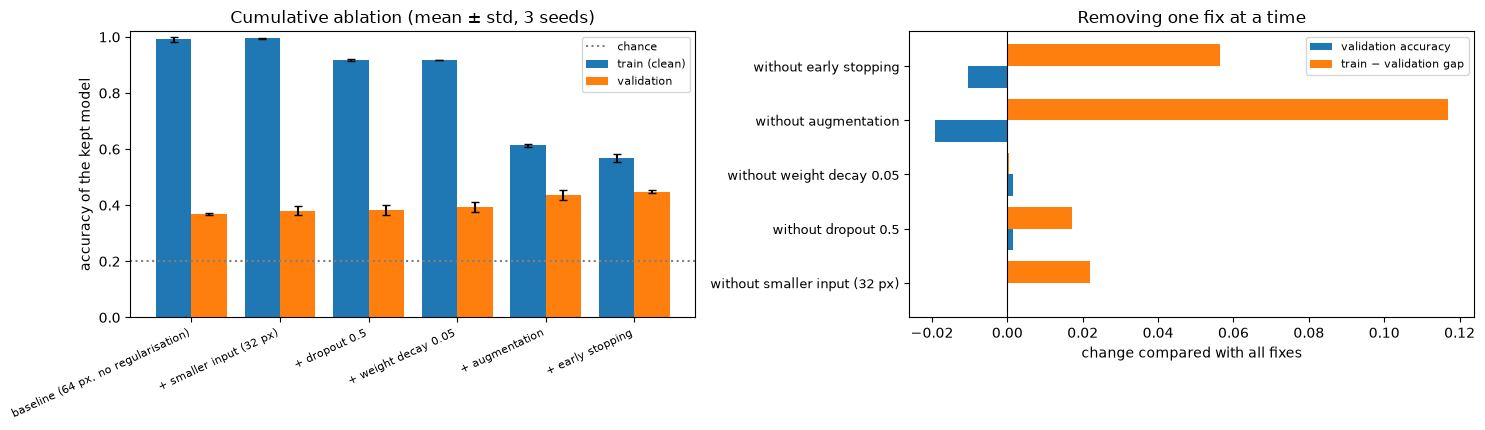

,val acc (mean),val acc (std),gap (mean),val acc change,gap change
config,,,,,
all fixes,0.447,0.005,0.120,0.000,0.000
without smaller input (32 px),0.447,0.007,0.142,0.000,0.022
without dropout 0.5,0.449,0.012,0.137,0.001,0.017
without weight decay 0.05,0.449,0.012,0.120,0.001,0.000
without augmentation,0.428,0.014,0.237,-0.019,0.117
without early stopping,0.437,0.019,0.176,-0.010,0.056


In [8]:
full_name = list(configs)[-1]
full = configs[full_name]
dropped = {"all fixes": full}
for name, change in FIXES:
    key = next(iter(change))
    dropped[f"without {name}"] = {**full, key: BASELINE[key]}

drop_rows = [{**row, "config": "all fixes"} for row in rows if row["config"] == full_name]   # already trained
for name, config in list(dropped.items())[1:]:
    for seed in SEEDS:
        result, h, _ = run(config, seed)
        drop_rows.append({"config": name, "seed": seed, **result})
        histories.setdefault(name, h)
drop_one = summarise(drop_rows)
drop_one["val acc change"] = drop_one["val acc (mean)"] - drop_one.loc["all fixes", "val acc (mean)"]
drop_one["gap change"] = drop_one["gap (mean)"] - drop_one.loc["all fixes", "gap (mean)"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
names = list(ablation.index)
x = np.arange(len(names))
axes[0].bar(x - 0.2, ablation["train acc (mean)"], 0.4, yerr=ablation["train acc (std)"].fillna(0), capsize=3,
            label="train (clean)")
axes[0].bar(x + 0.2, ablation["val acc (mean)"], 0.4, yerr=ablation["val acc (std)"].fillna(0), capsize=3,
            label="validation")
axes[0].axhline(0.2, color="grey", ls=":", label="chance")
axes[0].set_xticks(x, names, rotation=25, ha="right", fontsize=8)
axes[0].set(ylim=(0, 1.02), ylabel="accuracy of the kept model", title="Cumulative ablation (mean ± std, 3 seeds)")
axes[0].legend(fontsize=8)
others = drop_one.drop(index="all fixes")
y = np.arange(len(others))
axes[1].barh(y - 0.2, others["val acc change"], 0.4, label="validation accuracy")
axes[1].barh(y + 0.2, others["gap change"], 0.4, label="train − validation gap")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_yticks(y, others.index, fontsize=9)
axes[1].set(xlabel="change compared with all fixes", title="Removing one fix at a time")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_ablation.png", dpi=150, bbox_inches="tight")
plt.show()
drop_one[["val acc (mean)", "val acc (std)", "gap (mean)", "val acc change", "gap change"]].round(3)

**What we see.**
- **Removing augmentation costs the most:** −1.9 points of validation accuracy and +11.7 points of gap.
- **Removing early stopping:** −1.0 point and +5.6 points of gap.
- **The other three barely matter:** removing the smaller input, dropout or weight decay changes the accuracy by at most 0.2 points (noise) and the gap by at most 2.2 points.

**Why.**
- **Redundant fixes.** Once augmentation and early stopping are in, the other fixes have almost nothing left to do.
- **Weight decay does nothing measurable here.** With AdamW, each step shrinks the weights by lr × weight decay = 10⁻⁴ × 0.05 = 5 × 10⁻⁶, under 1 % over the whole training. That's far too little at this learning rate; a stronger value would be needed, and we didn't tune it.

**Order dependence.** In the cumulative ablation, dropout looked useful (gap −8 points) because it came *before* augmentation. Measured on its own here, its effect is covered by augmentation.

## 8. The FFN candidate

**Rule, fixed before the runs:** among every configuration tried above, keep the one with the highest mean validation accuracy. If others are within one standard deviation of it, keep the one with the fewest fixes, since it's simpler.

The frozen configuration is written in `museum/models.py` (`FFN_CANDIDATE`, `FFN_RECIPE`), so `07_comparison` and the guide use exactly this one. The cell checks that the two agree.

In [9]:
results = pd.concat([ablation, drop_one.drop(index="all fixes")])
every_config = {**configs, **{k: v for k, v in dropped.items() if k != "all fixes"}}
top = results["val acc (mean)"].idxmax()
threshold = results.loc[top, "val acc (mean)"] - np.nan_to_num(results.loc[top, "val acc (std)"])
close = [name for name in results.index if results.loc[name, "val acc (mean)"] >= threshold]
n_fixes = {name: sum(cfg[k] != BASELINE[k] for k in BASELINE) for name, cfg in every_config.items()}
chosen = min(close, key=lambda name: (n_fixes[name], -results.loc[name, "val acc (mean)"]))
chosen_config = every_config[chosen]
print(f"best: {top} | within one std: {close}")
print(f"chosen: {chosen} -> {chosen_config}")

frozen = {"size": FFN_CANDIDATE["img_size"], "dropout": FFN_CANDIDATE["dropout"],
          "weight_decay": FFN_RECIPE["weight_decay"], "augment": FFN_RECIPE["augment"],
          "patience": FFN_RECIPE["patience"]}
assert FFN_CANDIDATE["hidden"] == HIDDEN and FFN_RECIPE["batch_size"] == BATCH_SIZE
if FAST_RUN:
    print("FAST_RUN: too few epochs and seeds to check the selection")
else:
    assert FFN_RECIPE["lr"] == LR and FFN_RECIPE["max_epochs"] == EPOCHS_FIX
    assert frozen == chosen_config, "update FFN_CANDIDATE / FFN_RECIPE in museum/models.py"

n_params = count_parameters(StyleMLP(**FFN_CANDIDATE))
row = results.loc[chosen]
print(f"FFN candidate: {n_params:,} parameters ({4 * n_params / 1e6:.1f} MB); "
      f"val acc {row['val acc (mean)']:.3f} ± {row['val acc (std)']:.3f}, train-val gap {row['gap (mean)']:.3f}, "
      f"{row['epochs (mean)']:.0f} epochs and {row['train time (s) (mean)']:.0f} s to train")

best: without dropout 0.5 | within one std: ['+ early stopping', 'without smaller input (32 px)', 'without dropout 0.5', 'without weight decay 0.05']
chosen: without dropout 0.5 -> {'size': 32, 'dropout': 0.0, 'weight_decay': 0.05, 'augment': True, 'patience': 10}
FFN candidate: 820,229 parameters (3.3 MB); val acc 0.449 ± 0.012, train-val gap 0.137, 33 epochs and 4 s to train


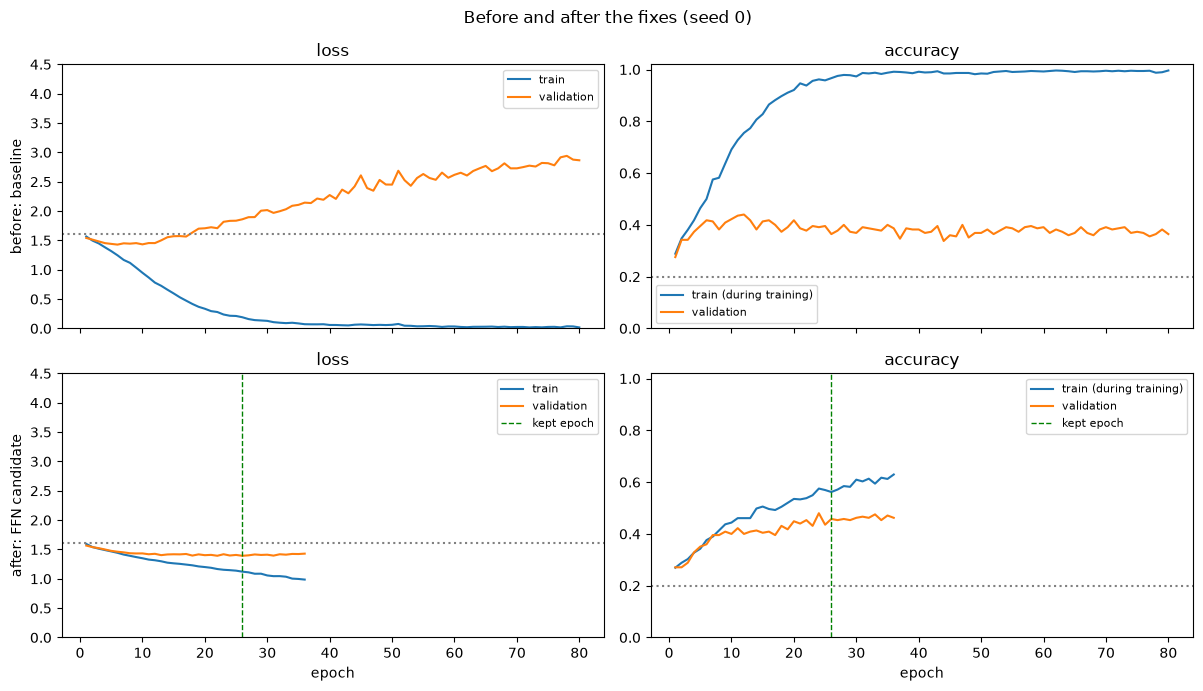

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, (name, label) in enumerate([(list(configs)[0], "before: baseline"), (chosen, "after: FFN candidate")]):
    h = histories[name]
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[row, 0].plot(epochs, h["train_loss"], label="train")
    axes[row, 0].plot(epochs, h["val_loss"], label="validation")
    axes[row, 0].axhline(math.log(5), color="grey", ls=":")
    axes[row, 1].plot(epochs, h["train_acc"], label="train (during training)")
    axes[row, 1].plot(epochs, h["val_acc"], label="validation")
    axes[row, 1].axhline(0.2, color="grey", ls=":")
    axes[row, 0].set(ylabel=label, title="loss", ylim=(0, 4.5))
    axes[row, 1].set(title="accuracy", ylim=(0, 1.02))
    if h["best_epoch"] is not None and h["best_epoch"] < len(h["train_loss"]) and name == chosen:
        for ax in axes[row]:
            ax.axvline(h["best_epoch"], color="green", ls="--", lw=1, label="kept epoch")
    for ax in axes[row]:
        ax.legend(fontsize=8)
axes[1, 0].set_xlabel("epoch")
axes[1, 1].set_xlabel("epoch")
fig.suptitle("Before and after the fixes (seed 0)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.**
- **The selection.** The best mean is *without dropout* (0.449 ± 0.012). Four configurations are within one standard deviation of it; among those with the fewest fixes it is the best.
- **The frozen FFN candidate:** 32 px, hidden layers 256 → 128, no dropout, AdamW (lr 1e-4, weight decay 0.05), augmentation, early stopping (patience 10, at most 80 epochs). Its size, accuracy and training time are printed above.
- **Before vs after.**
  - The baseline memorises its training set while its validation loss climbs to about 2.9.
  - The candidate's training and validation curves stay close, and training stops by itself (here at epoch 36, keeping epoch 26).
- **The weight decay stays.** The rule keeps it although it has no measurable effect (section 7); it's harmless.

**Where this leaves the FFN.** The overfitting is fixed (gap 62 → 14 points), but the validation accuracy is about 45 %, far from the 85 % target. The learning curve (section 5) already showed the ceiling of a network that ignores spatial structure. This candidate is the FFN entry in `07_comparison`.

## 9. The candidate's result file

We train the frozen candidate again with seed 0, through the same `run` as above, so it's the very same run. Its weights are saved to `checkpoints/ffn.pt`, which is not committed: `07_comparison` and the guide load it from there, and this notebook recreates it in a few seconds.

Then we measure what the comparison needs, the same way as for the other candidates (`museum.evaluation`):
- **validation accuracy, end to end** on the raw 128 px images: resize to 32 px, normalisation, network
- **parameters and size on disk**
- **CPU latency for one image**, with 1 and 2 threads (median and 95th percentile of 100 runs)
- **training time**

The test fields are added once, in `07_comparison`.

In [11]:
# Built from the selected configuration: equal to FFN_CANDIDATE / FFN_RECIPE (checked above), except in FAST_RUN.
model_config = {"img_size": chosen_config["size"], "hidden": HIDDEN, "dropout": chosen_config["dropout"]}
recipe = {**FFN_RECIPE, "lr": LR, "weight_decay": chosen_config["weight_decay"], "augment": chosen_config["augment"],
          "max_epochs": EPOCHS_FIX, "patience": chosen_config["patience"]}
result, h, candidate = run(chosen_config, seed=0)
CKPT_DIR.mkdir(exist_ok=True)
mean, std = norm_stats("train", model_config["img_size"])
torch.save({"state_dict": candidate.cpu().state_dict(), "config": model_config, "recipe": recipe,
            "mean": mean, "std": std}, CKPT_DIR / "ffn.pt")

X_val, y_val = get_arrays(128, "val")
cpu_model = StyleMLP(**model_config)
cpu_model.load_state_dict(torch.load(CKPT_DIR / "ffn.pt")["state_dict"])
predictor = TorchPredictor(cpu_model, model_config["img_size"], mean, std)
val_pred = predictor.predict(X_val)
val_acc = float((val_pred == y_val).mean())
assert abs(val_acc - result["val acc"]) <= 1 / len(y_val), "end to end must match the loader pipeline"

runs = 20 if FAST_RUN else 100
latency = {f"threads_{t}": benchmark_latency(predictor, X_val[0], n_threads=t, runs=runs) for t in (1, 2)}
row = results.loc[chosen]
seed_std = None if np.isnan(row["val acc (std)"]) else float(row["val acc (std)"])
path = save_result("ffn", {
    "config": {**model_config, **recipe, "normalize": "train", "mean": mean, "std": std, "seed": 0,
               "epochs_trained": len(h["val_acc"]), "best_epoch": h["best_epoch"],
               "val_acc_mean_over_seeds": float(row["val acc (mean)"]), "val_acc_std_over_seeds": seed_std,
               "seeds": SEEDS, "fast_run": FAST_RUN},
    "val_acc": val_acc, "n_params": total_parameters(cpu_model), "size_mb": model_size_mb(CKPT_DIR / "ffn.pt"),
    "latency_ms": latency, "train_time_s": float(sum(h["epoch_time"])),
}, results_dir=RESULTS_DIR)

print(f"wrote {path.relative_to(RESULTS_DIR.parent)}")
print(f"val acc (seed 0, end to end): {val_acc:.3f} | {total_parameters(cpu_model):,} parameters, "
      f"{model_size_mb(CKPT_DIR / 'ffn.pt'):.2f} MB | trained in {sum(h['epoch_time']):.1f} s, "
      f"{len(h['val_acc'])} epochs (kept epoch {h['best_epoch']})")
pd.DataFrame(latency).T.round(2).rename_axis("CPU latency (ms), batch 1")

wrote results/ffn.json
val acc (seed 0, end to end): 0.458 | 820,229 parameters, 3.28 MB | trained in 3.9 s, 36 epochs (kept epoch 26)


,median_ms,p95_ms
"CPU latency (ms), batch 1",,
threads_1,0.08,0.09
threads_2,0.08,0.09


**What we see.**
- **Accuracy:** the FFN candidate (seed 0) reaches **0.458** validation accuracy end to end on the raw images; the mean over 3 seeds is 0.449 ± 0.012.
- **Cost:** 820,229 parameters, 3.3 MB on disk, under 4 s to train, and **0.08 ms** per image on one CPU thread.

**Against the director's criteria** (PLAN §4), on validation for now:

| Criterion | Target | FFN | |
|---|---|---|---|
| CPU latency (1 thread, ×5 safety factor) | ≤ 40 ms measured | 0.08 ms | ✓ (500× under) |
| Footprint | ≤ 100 MB, trainable in < 1 h | 3.3 MB, 4 s | ✓ |
| Accuracy | ≥ 85 % | 45.8 % | ✗ far from it |

The FFN is cheap enough for any kiosk but not nearly accurate enough. The test-set check is in `07_comparison`.

## Summary: diagnosis and fixes

| Symptom | Evidence | Cause | Fix | Result |
|---|---|---|---|---|
| (sanity checks pass) | initial loss 1.610 ≈ ln 5; one batch overfitted in 7 steps | the pipeline works | none needed | |
| Training stuck at ln 5 for lr ≥ 1e-2 | 96–99.5 % of second-layer ReLUs dead | steps too large kill ReLU units | lr = 1e-4 | best val acc 0.44 |
| Train acc ~100 %, val acc ~40 %, val loss rising | 128 px: confidence on wrong answers 0.29 → 0.74 | overfitting: far more parameters than images | augmentation + early stopping (+ 32 px) | gap 62 → 12–14 points; val loss 2.86 → 1.38 |
| More data helps, but less and less | learning curve 0.37 → 0.46, flattening | no spatial structure in an FFN | a CNN (N3, N4) | see `07_comparison` |

**Takeaways.**
- **Monitoring found every failure:** curves, gradient and activation statistics, confidence, learning curve.
- **The ablation measured each fix:** augmentation and early stopping fix the overfitting; dropout and this weight decay add nothing on top.
- **The FFN candidate** (about 45 % validation accuracy) is frozen in `museum/models.py` for the comparison.